# 03 · Stylometry analysis and RQ1
Corpus-level stylometric features (Weeks 5–6), then the per-document feature-family decay
analysis for RQ1 (Weeks 7–8, `python -m src.run_rq1`).

In [1]:
import os, sys
ROOT = os.path.abspath("..")          # notebooks/ -> repository root
sys.path.insert(0, ROOT)
os.chdir(ROOT)
import pandas as pd
pd.set_option("display.max_colwidth", 120)

In [2]:
feat = pd.read_csv("experiments/stylometry_results/feature_comparison.csv")
feat[feat.paraphraser == "chatgpt"]

,paraphraser,generation,ttr,function_word_ratio,avg_sentence_length,punctuation_density,avg_word_length
0,chatgpt,T0,0.6290,0.4633,18.4412,16.7671,4.6785
1,chatgpt,T1,0.6701,0.4390,18.5026,15.7014,5.1063
2,chatgpt,T2,0.6779,0.4320,18.6495,15.4577,5.1653
3,chatgpt,T3,0.6821,0.4283,18.5509,15.4074,5.2152


## Change T0 → T3 per paraphraser

In [3]:
t0 = feat[feat.generation == "T0"].set_index("paraphraser").drop(columns="generation")
t3 = feat[feat.generation == "T3"].set_index("paraphraser").drop(columns="generation")
(t3 - t0).round(3)

,ttr,function_word_ratio,avg_sentence_length,punctuation_density,avg_word_length
paraphraser,,,,,
chatgpt,0.053,-0.035,0.110,-1.360,0.537
palm,0.006,0.007,-0.364,-0.866,0.142
dipper,-0.021,0.063,0.149,0.507,-0.272
dipper(low),-0.016,0.031,-0.170,-0.194,-0.125
dipper(high),0.147,0.085,3.825,4.682,-0.535
pegasus(full),0.029,0.032,-6.496,1.344,-0.210
pegasus(slight),0.008,0.015,-2.338,-0.517,-0.093
wordnet,0.045,-0.009,0.530,1.243,0.087


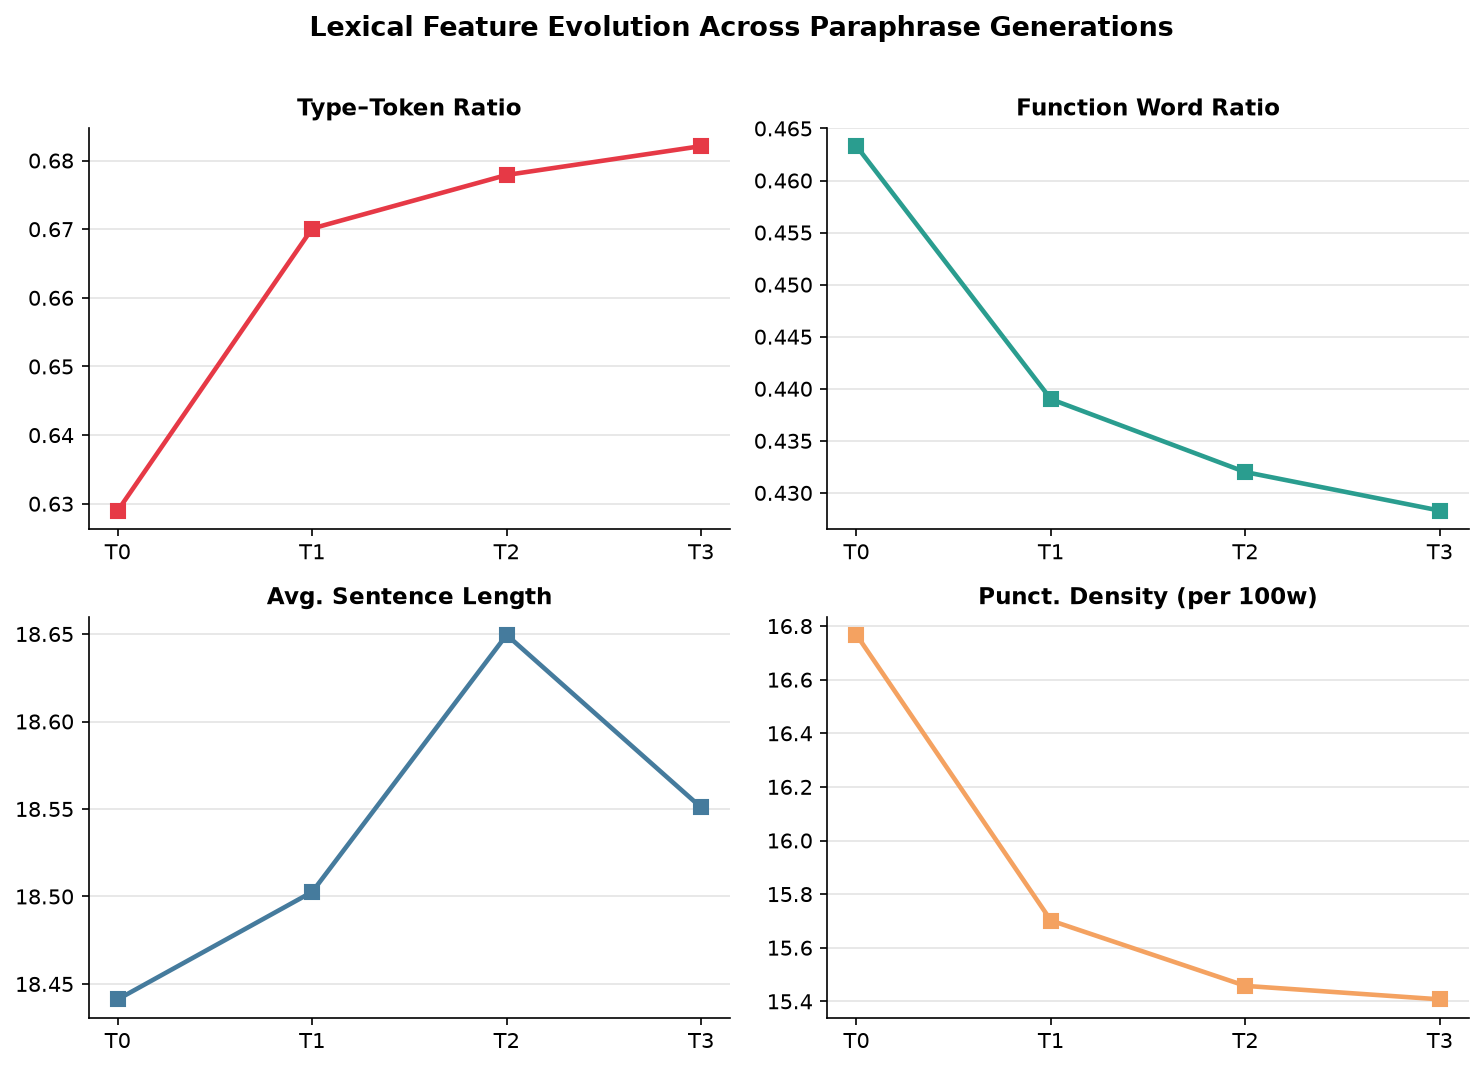

In [4]:
from IPython.display import Image
Image("figures/decay_curves/chatgpt/feature_evolution.png", width=650)

## RQ1: which planks are replaced first?
Retention = 1 − d(Tk, T0) / d(unrelated same-domain document, T0): 1 = unchanged, 0 = as different
as another author's document, < 0 = pushed beyond it.

In [5]:
rq1 = "experiments/stylometry_results/rq1"
rank = pd.read_csv(f"{rq1}/decay_ranking.csv")
rank[rank.paraphraser == "chatgpt"][["family", "T1", "T2", "T3", "share_of_loss_at_T1"]].round(3)

,family,T1,T2,T3,share_of_loss_at_T1
0,Readability,-0.133,-0.220,-0.308,0.866
1,Lexical richness,0.114,0.009,-0.059,0.837
2,Sentence shape,0.263,0.223,0.200,0.921
3,Word choice,0.275,0.241,0.210,0.918
4,Punctuation,0.279,0.229,0.213,0.916
5,Tree depth,0.286,0.251,0.222,0.917
6,Function words,0.292,0.251,0.226,0.915
7,Dependency labels,0.297,0.253,0.226,0.909
8,POS profile,0.395,0.357,0.336,0.911
9,Meaning (SBERT),0.882,0.863,0.853,0.804


In [6]:
ret = pd.read_csv(f"{rq1}/retention.csv")
ret[ret.generation == "T3"].pivot(index="family", columns="paraphraser", values="retention").round(2)

paraphraser,chatgpt,dipper,dipper(high),dipper(low),palm,pegasus(full),pegasus(slight),wordnet
family,,,,,,,,
Dependency labels,0.23,0.15,-0.36,0.41,0.32,0.14,0.55,0.46
Function words,0.23,0.18,-0.20,0.43,0.34,0.32,0.61,0.79
Lexical richness,-0.06,-0.07,-0.63,0.34,0.35,0.13,0.60,0.56
Meaning (SBERT),0.85,0.68,-0.10,0.87,0.85,0.79,0.91,0.75
POS profile,0.34,0.23,-0.44,0.49,0.39,0.14,0.59,0.67
Punctuation,0.21,0.10,-0.32,0.32,0.27,0.10,0.55,0.61
Readability,-0.31,0.22,-1.19,0.56,0.25,-0.40,0.42,0.64
Sentence shape,0.20,0.16,-0.99,0.49,0.27,-0.28,0.44,0.82
Tree depth,0.22,0.17,-0.52,0.40,0.29,-2.27,-0.14,0.55


## Is style lost faster than meaning? (paired Wilcoxon, Holm-corrected, T1)

In [7]:
tests = pd.read_csv(f"{rq1}/style_vs_meaning_tests.csv")
t1 = tests[(tests.generation == "T1") & (tests.paraphraser != "dipper(high)")]
print(f"{(t1.p_holm < 0.05).sum()}/{len(t1)} significant")
t1[t1.p_holm >= 0.05]

61/63 significant


,paraphraser,generation,family,median_nd_minus_meaning,rank_biserial,p,p_holm
190,wordnet,T1,Function words,-0.009167,0.011526,0.395814,0.791628
193,wordnet,T1,Sentence shape,-0.032831,-0.279275,1.000000,1.000000


## Direction of change T0 → T3 (paraphraser fingerprints)

In [8]:
shifts = pd.read_csv(f"{rq1}/feature_shifts.csv")
shifts.pivot(index="feature", columns="paraphraser", values="cohens_dz").round(2)

paraphraser,chatgpt,dipper,dipper(high),dipper(low),palm,pegasus(full),pegasus(slight),wordnet
feature,,,,,,,,
avg_word_length,1.50,-0.78,-0.79,-0.56,0.53,-0.69,-0.48,0.51
fk_grade,1.05,-0.24,-0.09,-0.12,0.35,-1.67,-1.08,0.48
mattr,0.60,-0.76,0.28,-0.62,-0.26,-0.53,-0.34,1.15
max_tree_depth,-0.05,-0.18,-0.57,-0.09,-0.13,-0.36,-0.14,-0.19
mean_dep_distance,-0.25,0.20,0.25,0.09,-0.20,0.14,0.08,0.47
mean_sentence_length,0.13,0.12,0.27,0.10,0.01,-1.04,-0.75,0.20
mean_tree_depth,0.45,-0.04,0.01,0.04,0.28,-1.36,-0.81,-0.25
n_words,-0.41,-0.62,-0.99,-0.45,-0.42,-0.95,-0.95,0.53
pos_ADJ,0.34,-0.14,-0.40,-0.03,0.09,-0.18,-0.09,0.20


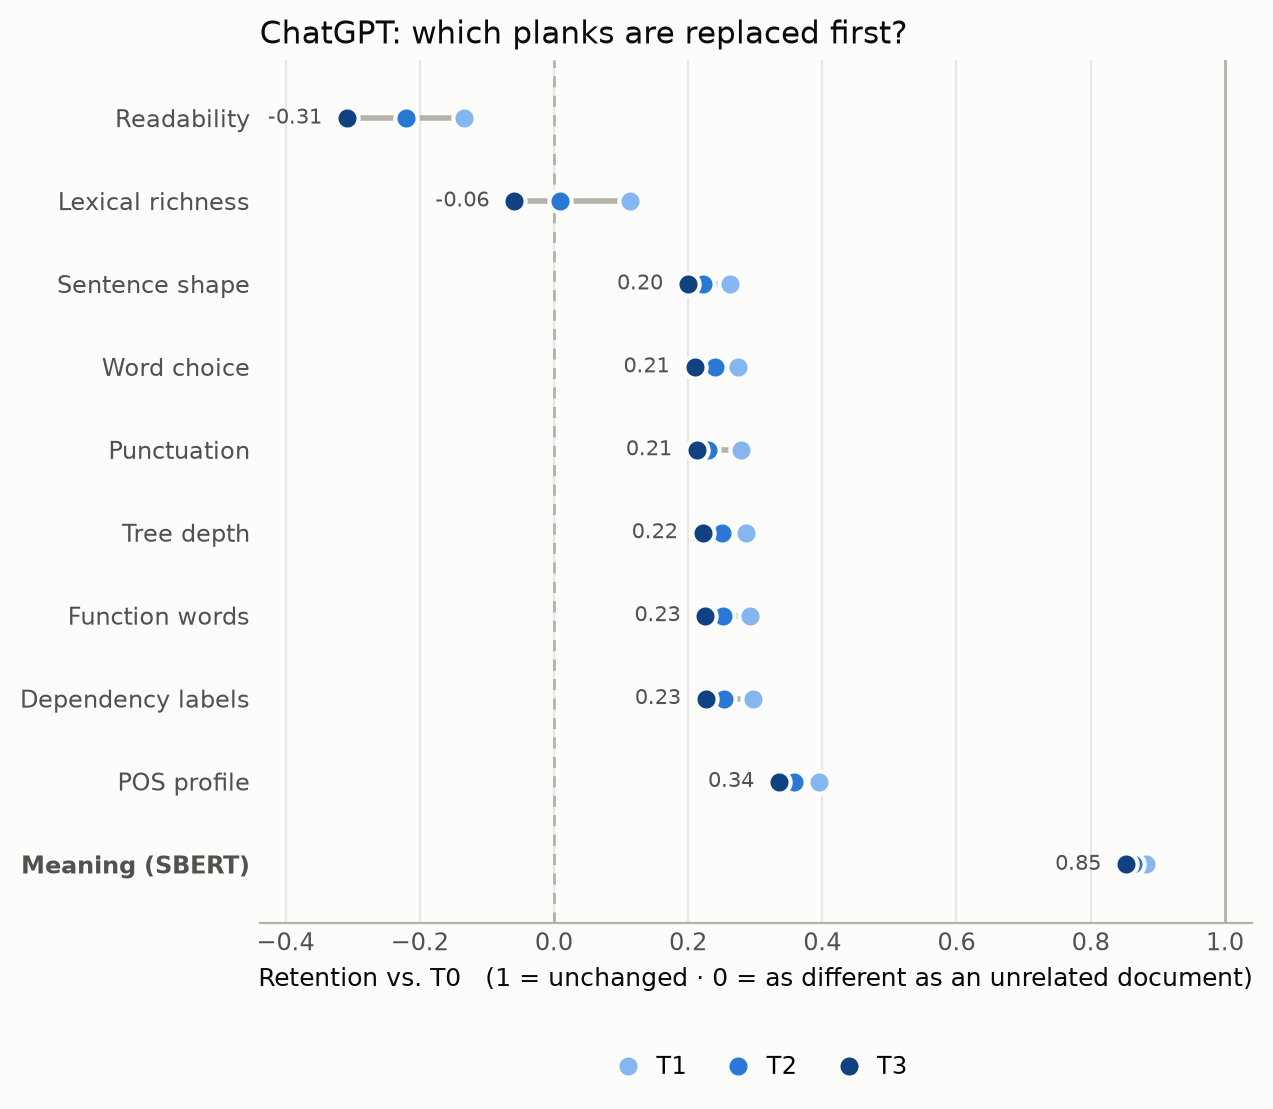

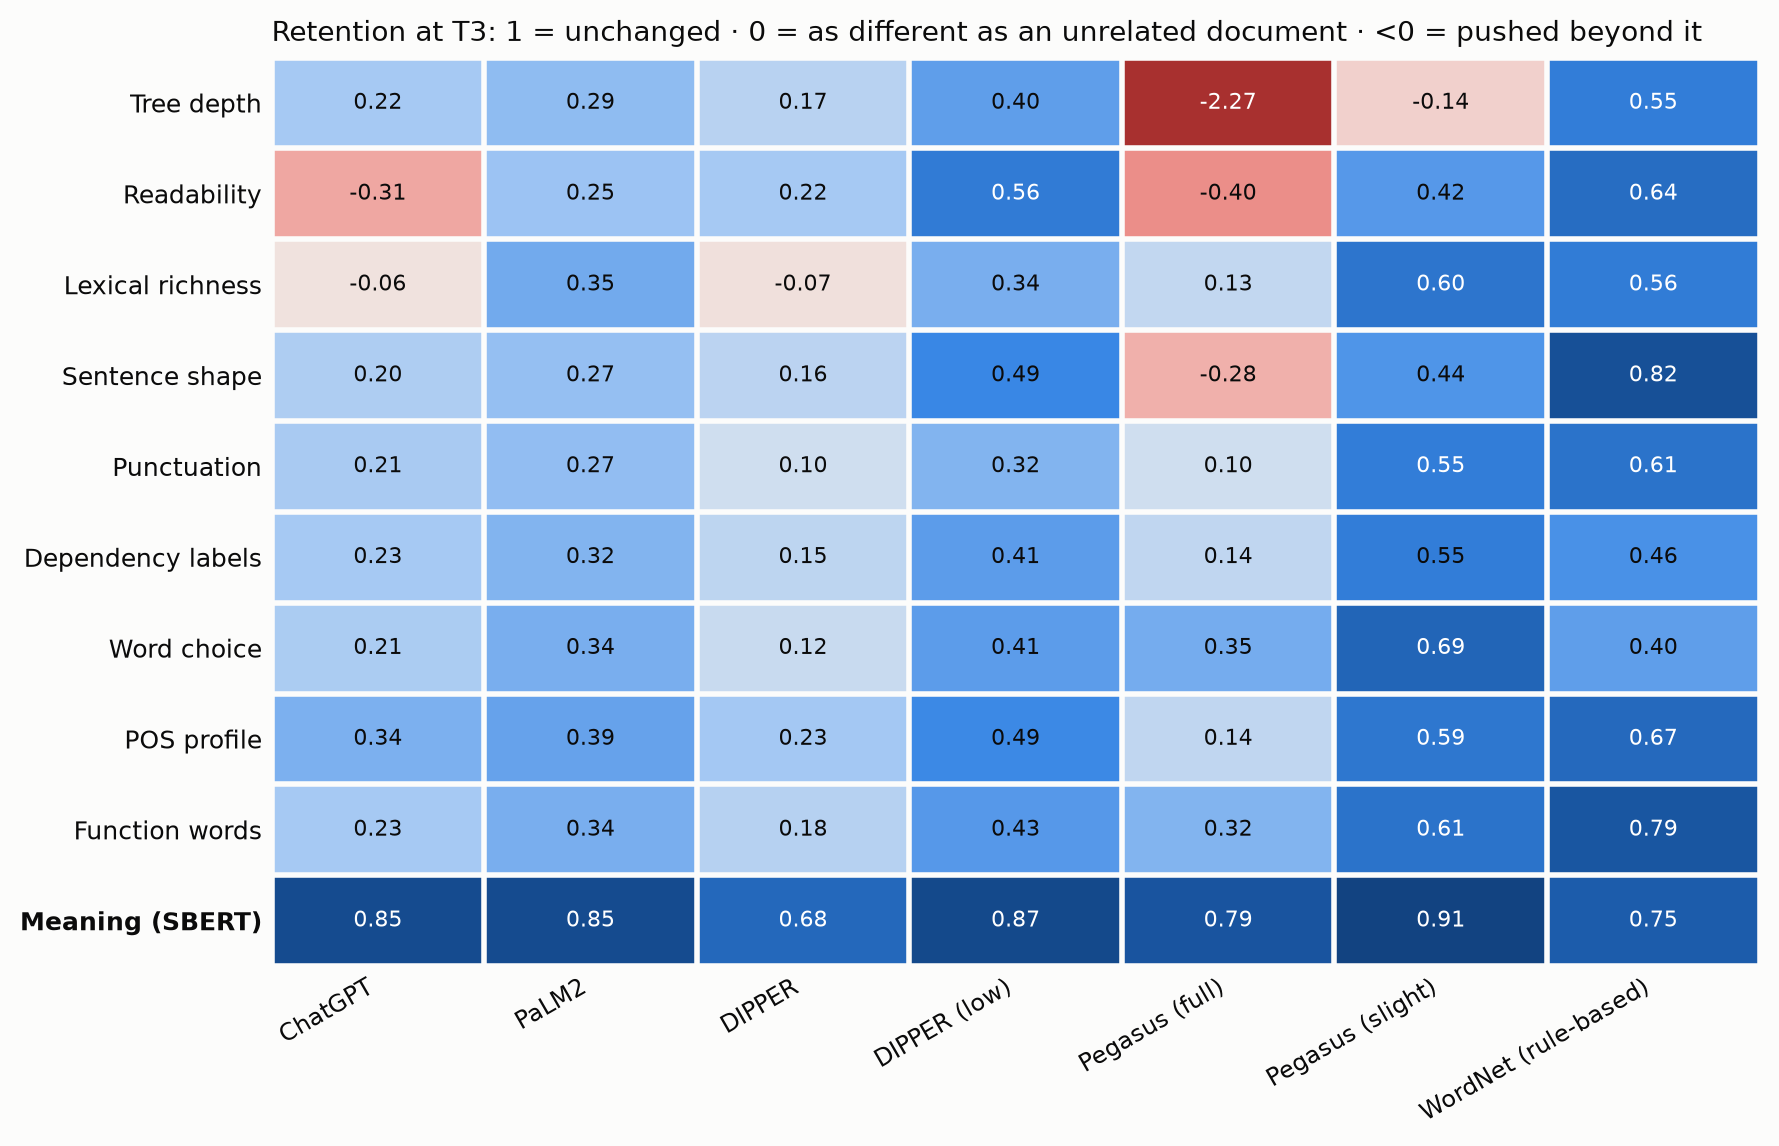

In [9]:
from IPython.display import Image, display
display(Image("figures/decay_curves/chatgpt/linguistic_delta.png", width=600))
display(Image("figures/decay_curves/retention_heatmap.png", width=750))